In [2]:
import pandas as pd
from pathlib import Path
import matplotlib.pyplot as plt
from pm import config

data = pd.read_csv(config.RAW_DATA)

In [3]:
print(data.shape)
print(data.info())

(10000, 14)
<class 'pandas.DataFrame'>
RangeIndex: 10000 entries, 0 to 9999
Data columns (total 14 columns):
 #   Column               Non-Null Count  Dtype  
---  ------               --------------  -----  
 0   UID                  10000 non-null  int64  
 1   Product ID           10000 non-null  str    
 2   Type                 10000 non-null  str    
 3   Air temperature      10000 non-null  float64
 4   Process temperature  10000 non-null  float64
 5   Rotational speed     10000 non-null  int64  
 6   Torque               10000 non-null  float64
 7   Tool wear            10000 non-null  int64  
 8   Machine failure      10000 non-null  int64  
 9   TWF                  10000 non-null  int64  
 10  HDF                  10000 non-null  int64  
 11  PWF                  10000 non-null  int64  
 12  OSF                  10000 non-null  int64  
 13  RNF                  10000 non-null  int64  
dtypes: float64(3), int64(9), str(2)
memory usage: 1.1 MB
None


In [4]:
print(data.describe())

               UID  Air temperature  Process temperature  Rotational speed  \
count  10000.00000     10000.000000         10000.000000      10000.000000   
mean    5000.50000       300.004930           310.005560       1538.776100   
std     2886.89568         2.000259             1.483734        179.284096   
min        1.00000       295.300000           305.700000       1168.000000   
25%     2500.75000       298.300000           308.800000       1423.000000   
50%     5000.50000       300.100000           310.100000       1503.000000   
75%     7500.25000       301.500000           311.100000       1612.000000   
max    10000.00000       304.500000           313.800000       2886.000000   

             Torque     Tool wear  Machine failure           TWF  \
count  10000.000000  10000.000000     10000.000000  10000.000000   
mean      39.986910    107.951000         0.033900      0.004600   
std        9.968934     63.654147         0.180981      0.067671   
min        3.800000      

In [5]:
data["Failure addition"] = data["TWF"] + data["HDF"] + data["PWF"] + data["OSF"] + data["RNF"]
data["Known Failure"] = data["Failure addition"] > 0

print(pd.crosstab(data["Known Failure"], data["Machine failure"], rownames=["Known Failure"], colnames=["Machine failure"]))

failures = data[data["Machine failure"] == 1]
print(failures["Failure addition"].value_counts())

weird = data[(data["Machine failure"] == 0) & (data["Failure addition"] > 0)]
print(weird[["TWF", "HDF", "PWF", "OSF", "RNF"]].sum())


Machine failure     0    1
Known Failure             
False            9643    9
True               18  330
Failure addition
1    306
2     23
0      9
3      1
Name: count, dtype: int64
TWF     0
HDF     0
PWF     0
OSF     0
RNF    18
dtype: int64


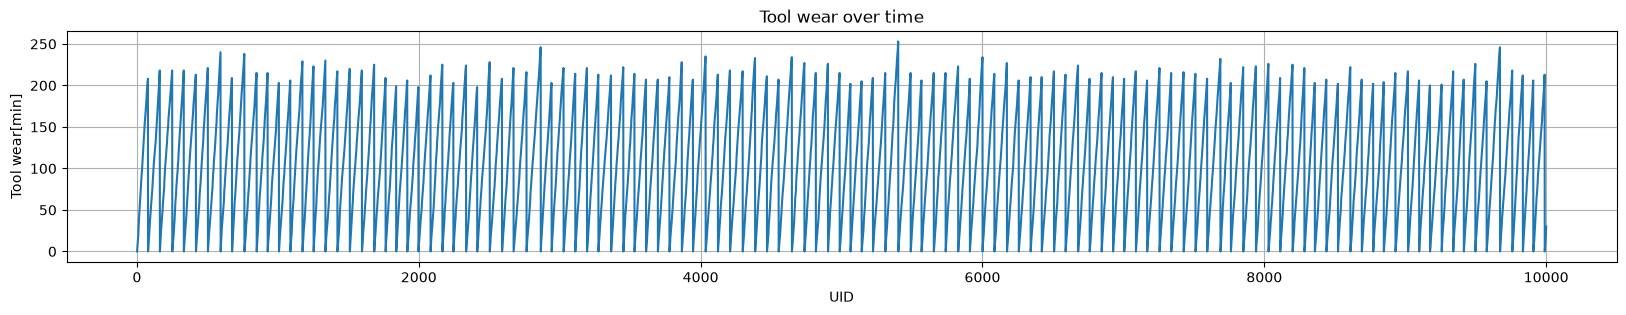

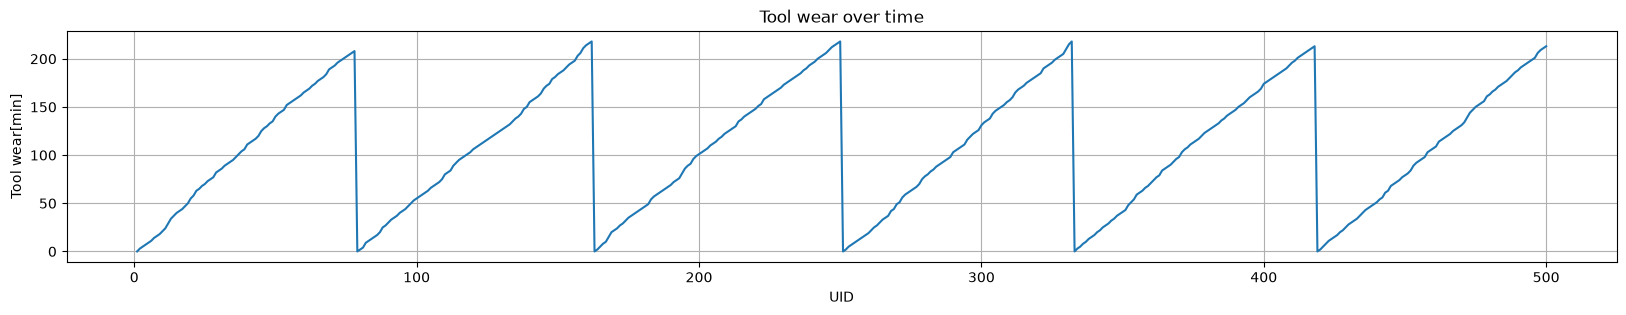

In [6]:
plt.figure(figsize=(20, 3))

plt.plot(data["UID"], data["Tool wear"])

plt.title("Tool wear over time")
plt.xlabel("UID")
plt.ylabel("Tool wear[min]")
plt.grid(True)  

plt.show()

data500 = data.head(500)

plt.figure(figsize=(20, 3))

plt.plot(data500["UID"], data500["Tool wear"])

plt.title("Tool wear over time")
plt.xlabel("UID")
plt.ylabel("Tool wear[min]")
plt.grid(True)  

plt.show()

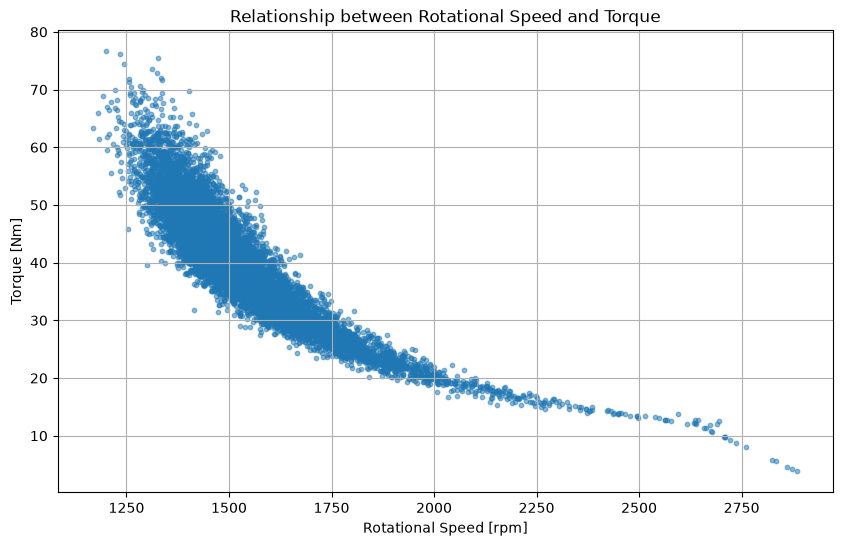

In [7]:
plt.figure(figsize=(10, 6))

plt.scatter(data["Rotational speed"], data["Torque"], alpha=0.5, s=10)

plt.title("Relationship between Rotational Speed and Torque")
plt.xlabel("Rotational Speed [rpm]")
plt.ylabel("Torque [Nm]")
plt.grid(True)  

plt.show()

In [8]:
data_proces = data.drop(columns=["UID","Product ID", "Type","Machine failure", "TWF", "HDF", "PWF", "OSF", "RNF", "Failure addition", "Known Failure"])

print(data_proces.corr())

                     Air temperature  Process temperature  Rotational speed  \
Air temperature             1.000000             0.876107          0.022670   
Process temperature         0.876107             1.000000          0.019277   
Rotational speed            0.022670             0.019277          1.000000   
Torque                     -0.013778            -0.014061         -0.875027   
Tool wear                   0.013853             0.013488          0.000223   

                       Torque  Tool wear  
Air temperature     -0.013778   0.013853  
Process temperature -0.014061   0.013488  
Rotational speed    -0.875027   0.000223  
Torque               1.000000  -0.003093  
Tool wear           -0.003093   1.000000  


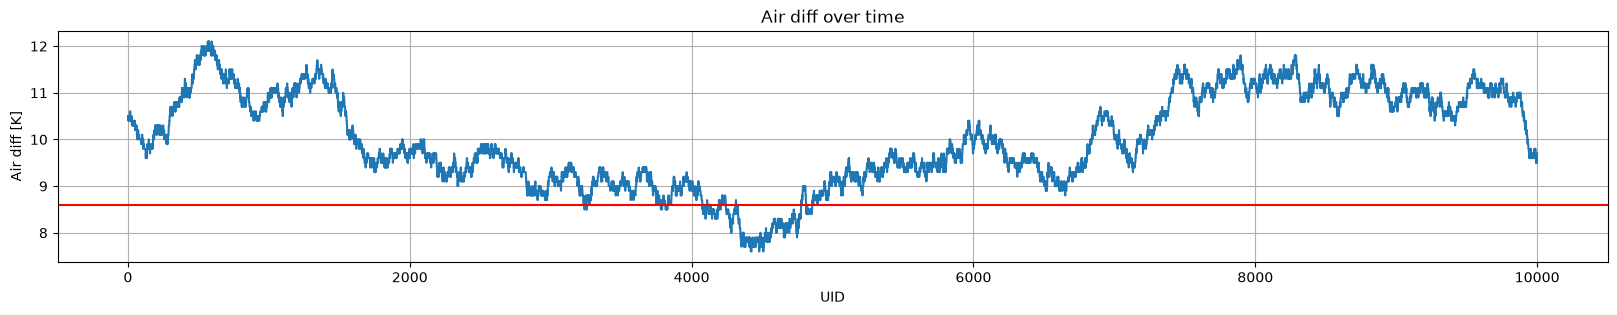

In [9]:
plt.figure(figsize=(20, 3))

plt.plot(data["UID"], data["Process temperature"]-data["Air temperature"])

plt.axhline(y = 8.6, color = "red")

plt.title("Air diff over time")
plt.xlabel("UID")
plt.ylabel("Air diff [K]")
plt.grid(True)  

plt.show()

In [ ]:
df = pd.read_csv(config.PROCESSED_DATA)

print(df["power_w"].describe())
print()
print((df["power_w"] < 3500).sum())
print((df["power_w"] > 9000).sum())


count    10000.000000
mean      6279.744953
std       1067.418295
min       1148.440610
25%       5561.184484
50%       6271.027344
75%       7003.002724
max      10469.923005
Name: power_w, dtype: float64

Under 3500: power_w
True    31
Name: count, dtype: int64
